# BÀI THỰC HÀNH SỐ 2 - PHẦN IV - BÀI 7 (Trang 27–31)
## Ứng dụng nhận dạng chữ số viết tay (MNIST `load_digits`) với cây quyết định ID3

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Môn học:** Khai phá dữ liệu (Data Mining)
- **Mục tiêu:** Xây dựng mô hình nhận dạng chữ số viết tay từ bộ dữ liệu ảnh 8×8 có sẵn trong `sklearn.datasets.load_digits()`, đánh giá mô hình cây quyết định ID3 (`criterion="entropy"`, `random_state=33`) trên tập kiểm thử (20%), và áp dụng nhận dạng hai ảnh chữ số viết tay thực tế (`test_image_Bai7_1.jpg` và `test_image_Bai7_2.jpg`).

## Bước 1: Chuẩn bị các thư viện cần thiết và hàm nạp dữ liệu

In [1]:
%matplotlib inline
import os
import sys
import subprocess

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
from PIL import Image, ImageOps
from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"

DATASET_DRIVE_URL = "https://drive.google.com/drive/folders/1KK--zL3h4hWrfIl--FIcrww3dLx-epiB?usp=sharing"


def get_dataset_path(filename: str, fallback_filenames=None, gdrive_file_id: str = None) -> str:
    """Tìm đường dẫn tệp dữ liệu cục bộ, trên Google Drive (Colab), hoặc tải bằng gdown."""
    candidates = [filename] + list(fallback_filenames or [])
    for name in candidates:
        local_path = os.path.join("Dataset", name)
        if os.path.exists(local_path):
            return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        for name in candidates:
            colab_path = os.path.join("/content/drive/MyDrive/Dataset", name)
            if os.path.exists(colab_path):
                return colab_path

    os.makedirs("Dataset", exist_ok=True)
    local_path = os.path.join("Dataset", filename)
    if gdrive_file_id:
        subprocess.run(
            [sys.executable, "-m", "gdown", f"https://drive.google.com/uc?id={gdrive_file_id}", "-O", local_path],
            check=True,
        )
    else:
        subprocess.run(
            [sys.executable, "-m", "gdown", "--folder", DATASET_DRIVE_URL, "-O", "Dataset"],
            check=True,
        )
    for name in candidates:
        candidate_path = os.path.join("Dataset", name)
        if os.path.exists(candidate_path):
            return candidate_path
    raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu tại {local_path}")


print(f"{STUDENT_NAME} - {MSSV}")
print(f"scikit-learn version: {sklearn.__version__} | numpy version: {np.__version__}")

Nguyễn Phạm Bảo Khanh - 6451071033
scikit-learn version: 1.9.1 | numpy version: 2.5.5


## Bước 2 & 3: Tải dữ liệu `load_digits` và biểu diễn 4 mẫu huấn luyện (0, 1, 2, 3)

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

# The digits dataset
digits = datasets.load_digits()
print(f"Số lượng ảnh: {len(digits.images)} | Kích thước mỗi ảnh: {digits.images[0].shape}")
print(f"Khoảng giá trị pixel trong load_digits: [{digits.images.min():.0f}, {digits.images.max():.0f}]")
print(f"Các lớp chữ số: {np.unique(digits.target).tolist()}")

Nguyễn Phạm Bảo Khanh - 6451071033
Số lượng ảnh: 1797 | Kích thước mỗi ảnh: (8, 8)
Khoảng giá trị pixel trong load_digits: [0, 16]
Các lớp chữ số: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Nguyễn Phạm Bảo Khanh - 6451071033


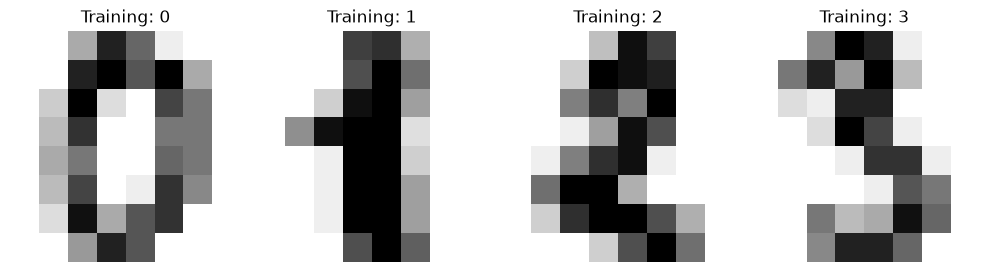

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.
_, axes = plt.subplots(1, 4, figsize=(10, 3))
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)
plt.tight_layout()
plt.show()

## Bước 4–7: Chuyển đổi ảnh 8×8 thành vector 1×64, chia dữ liệu (80%/20%) và huấn luyện cây ID3

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
print(f"Kích thước dữ liệu sau khi làm phẳng: {data.shape}")

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước dữ liệu sau khi làm phẳng: (1797, 64)


In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

# Create a classifier: a decision tree classifier (ID3 - criterion="entropy")
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)

# Split data into train (80%) and test (20%) subsets without shuffling
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False
)

print(f"Số mẫu huấn luyện: {len(X_train)} | Số mẫu kiểm thử: {len(X_test)}")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

Nguyễn Phạm Bảo Khanh - 6451071033
Số mẫu huấn luyện: 1437 | Số mẫu kiểm thử: 360
X_train: (1437, 64) | X_test: (360, 64)


In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

# We learn the digits on the first part of the digits
classifier.fit(X_train, y_train)
print("Đã huấn luyện xong cây ID3:", classifier)
print(f"Độ sâu cây (depth): {classifier.get_depth()} | Số nút lá (leaves): {classifier.get_n_leaves()}")

Nguyễn Phạm Bảo Khanh - 6451071033
Đã huấn luyện xong cây ID3: DecisionTreeClassifier(criterion='entropy', random_state=33)
Độ sâu cây (depth): 10 | Số nút lá (leaves): 113


## Bước 8–9: Dự đoán nhãn tập kiểm thử và biểu diễn một vài kết quả dự đoán

> **Lưu ý hiệu chỉnh so với tài liệu PDF (Trang 28):** Trong tài liệu hướng dẫn gốc, câu lệnh vẽ 4 ảnh kiểm thử viết `digits.images[n_samples // 2:]` (lấy từ chỉ số `898`, vốn thuộc ví dụ chia 50/50 của scikit-learn) trong khi dữ liệu được chia theo tỷ lệ 80/20 (`test_size=0.2`, `shuffle=False`), dẫn đến nhãn dự đoán `[2, 3, 4, 5]` bị ghép nhầm với ảnh `[8, 8, 4, 9]` ở nửa sau tập dữ liệu. Ta hiệu chỉnh thành `digits.images[-len(X_test):]` (từ chỉ số `1437`) để hiển thị đúng 4 ảnh kiểm thử thực tế (`2, 3, 4, 5`) khớp hoàn toàn với `X_test` và `predicted`.

Nguyễn Phạm Bảo Khanh - 6451071033
4 nhãn thực tế đầu tập test:  [2, 3, 4, 5]
4 nhãn dự đoán đầu tập test: [2, 3, 4, 5]


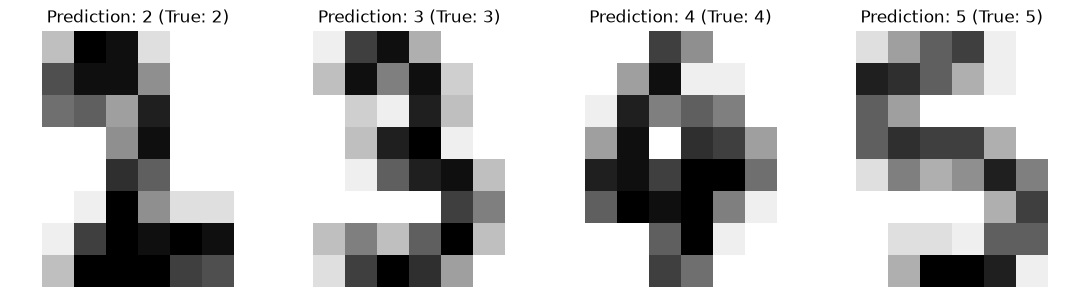

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

# Now predict the value of the digit on the second part:
predicted = classifier.predict(X_test)
print("4 nhãn thực tế đầu tập test: ", y_test[:4].tolist())
print("4 nhãn dự đoán đầu tập test:", predicted[:4].tolist())

# Fixed slice: digits.images[-len(X_test):] aligns with X_test for test_size=0.2, shuffle=False
# (instead of digits.images[n_samples // 2:] from the PDF's 50/50 split snippet)
_, axes = plt.subplots(1, 4, figsize=(11, 3))
images_and_predictions = list(zip(digits.images[-len(X_test):], predicted))
for ax, (image, prediction), actual in zip(axes, images_and_predictions[:4], y_test[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Prediction: {prediction} (True: {actual})")
plt.tight_layout()
plt.show()

## Bước 10: Đánh giá thông số cây ID3 và vẽ ma trận nhầm lẫn

> **Ghi chú tương thích `scikit-learn` hiện đại (`1.9.1`):** Hàm `metrics.plot_confusion_matrix` trong tài liệu cũ đã bị loại bỏ từ `scikit-learn 1.2` và được thay thế bằng `metrics.ConfusionMatrixDisplay.from_estimator`.

Nguyễn Phạm Bảo Khanh - 6451071033
Accuracy trên tập kiểm thử (360 mẫu): 0.797222 (79.72%)

Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360




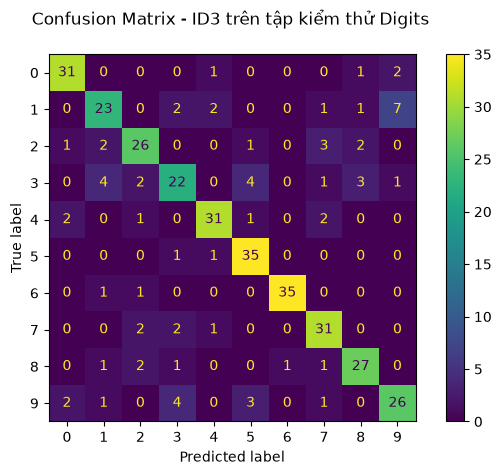

Confusion matrix:
[[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  0  0  1  0  3  2  0]
 [ 0  4  2 22  0  4  0  1  3  1]
 [ 2  0  1  0 31  1  0  2  0  0]
 [ 0  0  0  1  1 35  0  0  0  0]
 [ 0  1  1  0  0  0 35  0  0  0]
 [ 0  0  2  2  1  0  0 31  0  0]
 [ 0  1  2  1  0  0  1  1 27  0]
 [ 2  1  0  4  0  3  0  1  0 26]]


In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

acc = metrics.accuracy_score(y_test, predicted)
print(f"Accuracy trên tập kiểm thử (360 mẫu): {acc:.6f} ({acc * 100:.2f}%)\n")
print(
    "Classification report for classifier %s:\n%s\n"
    % (classifier, metrics.classification_report(y_test, predicted))
)

disp = metrics.ConfusionMatrixDisplay.from_estimator(classifier, X_test, y_test)
disp.figure_.suptitle("Confusion Matrix - ID3 trên tập kiểm thử Digits")
plt.tight_layout()
plt.show()
print("Confusion matrix:\n%s" % disp.confusion_matrix)

## Bước 11: Nhận dạng ảnh chữ số viết tay thực tế từ Google Drive

Thư mục Google Drive của bài thực hành chứa **2 ảnh kiểm thử thực tế**:
- `test_image_Bai7_1.jpg` (chữ số viết tay `1`, đồng thời có bản trùng tên `test_image_Bai7.jpg` trên Drive).
- `test_image_Bai7_2.jpg` (chữ số viết tay `2`).

Quy trình tiền xử lý theo hướng dẫn PDF (Trang 30–31):
1. Đọc ảnh màu, chuyển sang ảnh mức xám (`convert("L")`), co giãn về kích thước `8×8` và đảo màu (`ImageOps.invert`) để nét chữ có giá trị cao trên nền tối giống định dạng `load_digits`.
2. Làm phẳng thành vector `1×64` và chuẩn hóa tách nền/nét với ngưỡng `109`: các pixel `> 109` gán `155`, các pixel `< 110` gán `0`.
3. Kiểm tra thêm thang chuẩn hóa `0..16` (gần với thang pixel `0..16` của `load_digits`: nhị phân `> 109 -> 16` và chuẩn hóa min-max liên tục `0..16`) để đối chiếu hành vi của cây quyết định.

Nguyễn Phạm Bảo Khanh - 6451071033
Tệp ảnh: Dataset\test_image_Bai7_1.jpg | Kích thước gốc: (412, 411) | Nhãn thực tế: 1
Khoảng giá trị im2arr (8x8 sau đảo màu): [74, 139]
Ma trận im2arr (8x8):
[[ 80  80  80  79 112 104  89  90]
 [ 79  79  78  89 125  97  90  90]
 [ 79  78  78 120 126  95  92  90]
 [ 77  77  96 115 126  97  92  91]
 [ 76  74 107  93 125  97  93  92]
 [ 77  76  83  85 124  95  93  92]
 [ 78  79  79  87 123  93  94  93]
 [ 81  81  87 116 139 106  96  96]]

Vector img1d sau chuẩn hóa PDF (>109 -> 155, <110 -> 0):
[[  0   0   0   0 155   0   0   0   0   0   0   0 155   0   0   0   0   0
    0 155 155   0   0   0   0   0   0 155 155   0   0   0   0   0   0   0
  155   0   0   0   0   0   0   0 155   0   0   0   0   0   0   0 155   0
    0   0   0   0   0 155 155   0   0   0]]
-> Kết quả dự đoán ID3 (chuẩn hóa PDF 0/155):      1
-> Kết quả dự đoán ID3 (nhị phân thang 0/16):     1
-> Kết quả dự đoán ID3 (min-max liên tục 0..16):  8


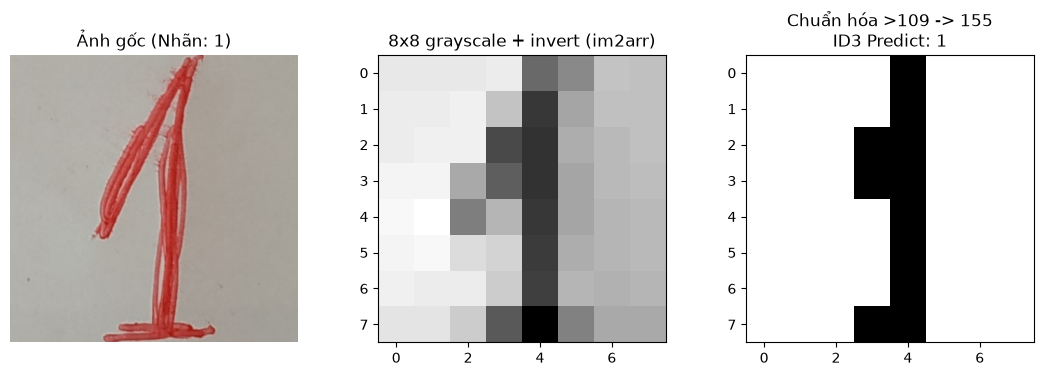

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")


def evaluate_handwritten_image(img_path: str, clf, expected_digit: int, threshold: int = 109):
    """Đọc ảnh chữ số viết tay, tiền xử lý 8x8, hiển thị trực quan và dự đoán bằng ID3."""
    orig_img = Image.open(img_path)

    # Open, convert to grayscale, resize to 8x8, and invert
    img_8x8 = ImageOps.invert(orig_img.convert("L").resize((8, 8)))
    im2arr = np.array(img_8x8)

    # Flatten 8x8 -> 1x64 and apply PDF threshold normalization (> 109 -> 155, < 110 -> 0)
    img1d = im2arr.reshape([1, 64]).copy()
    img1d[img1d > threshold] = 155
    img1d[img1d < threshold + 1] = 0
    pred_pdf = int(clf.predict(img1d)[0])

    # Binary 0..16 scaling and continuous min-max 0..16 scaling for comparison
    img1d_bin16 = np.where(im2arr.reshape([1, 64]) > threshold, 16, 0)
    pred_bin16 = int(clf.predict(img1d_bin16)[0])

    span = max(1, int(im2arr.max()) - int(im2arr.min()))
    img1d_minmax16 = np.round((im2arr - im2arr.min()) / span * 16).reshape([1, 64])
    pred_minmax16 = int(clf.predict(img1d_minmax16)[0])

    print(f"Tệp ảnh: {img_path} | Kích thước gốc: {orig_img.size} | Nhãn thực tế: {expected_digit}")
    print(f"Khoảng giá trị im2arr (8x8 sau đảo màu): [{im2arr.min()}, {im2arr.max()}]")
    print("Ma trận im2arr (8x8):")
    print(im2arr)
    print("\nVector img1d sau chuẩn hóa PDF (>109 -> 155, <110 -> 0):")
    print(img1d)
    print(f"-> Kết quả dự đoán ID3 (chuẩn hóa PDF 0/155):      {pred_pdf}")
    print(f"-> Kết quả dự đoán ID3 (nhị phân thang 0/16):     {pred_bin16}")
    print(f"-> Kết quả dự đoán ID3 (min-max liên tục 0..16):  {pred_minmax16}")

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
    axes[0].imshow(orig_img)
    axes[0].set_title(f"Ảnh gốc (Nhãn: {expected_digit})")
    axes[0].axis("off")

    axes[1].imshow(im2arr, cmap=plt.cm.gray_r, interpolation="nearest")
    axes[1].set_title("8x8 grayscale + invert (im2arr)")

    axes[2].imshow(img1d.reshape(8, 8), cmap=plt.cm.gray_r, interpolation="nearest")
    axes[2].set_title(f"Chuẩn hóa >{threshold} -> 155\nID3 Predict: {pred_pdf}")

    plt.tight_layout()
    plt.show()
    return pred_pdf, pred_bin16, pred_minmax16


img1_path = get_dataset_path(
    "test_image_Bai7_1.jpg",
    fallback_filenames=["test_image_Bai7.jpg"],
    gdrive_file_id="1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx",
)
pred1_pdf, pred1_bin16, pred1_mm16 = evaluate_handwritten_image(
    img1_path, classifier, expected_digit=1, threshold=109
)

Nguyễn Phạm Bảo Khanh - 6451071033
Tệp ảnh: Dataset\test_image_Bai7_2.jpg | Kích thước gốc: (385, 385) | Nhãn thực tế: 2
Khoảng giá trị im2arr (8x8 sau đảo màu): [73, 151]
Ma trận im2arr (8x8):
[[ 78  80 113 124 115  94  87  86]
 [ 73  99 129  85 101 123  90  88]
 [ 73 100 151  86  91 130  94  88]
 [ 76  83 114  89 116 126  90  89]
 [ 79  78  77  97 123  96  90  89]
 [ 81  79  84 125  92  88  89  90]
 [ 82  79 125 116 103 110 105 100]
 [ 83  99 141 135 140 133 107  92]]

Vector img1d sau chuẩn hóa PDF (>109 -> 155, <110 -> 0):
[[  0   0 155 155 155   0   0   0   0   0 155   0   0 155   0   0   0   0
  155   0   0 155   0   0   0   0 155   0 155 155   0   0   0   0   0   0
  155   0   0   0   0   0   0 155   0   0   0   0   0   0 155 155   0 155
    0   0   0   0 155 155 155 155   0   0]]
-> Kết quả dự đoán ID3 (chuẩn hóa PDF 0/155):      2
-> Kết quả dự đoán ID3 (nhị phân thang 0/16):     2
-> Kết quả dự đoán ID3 (min-max liên tục 0..16):  2


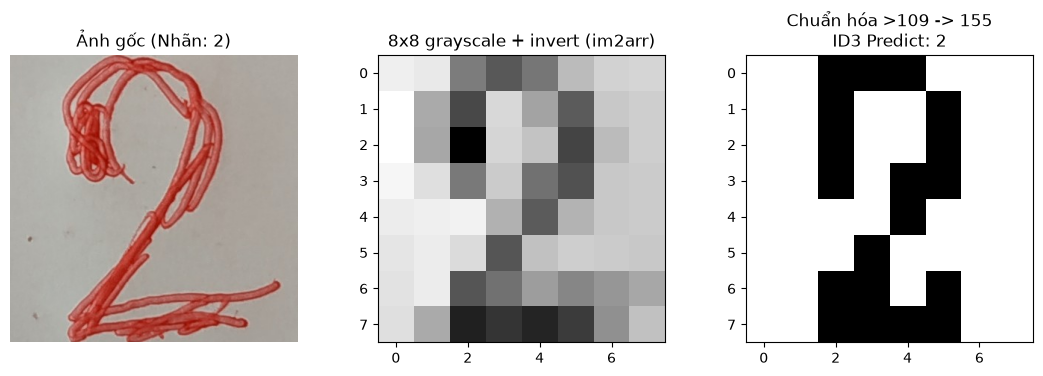

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

img2_path = get_dataset_path(
    "test_image_Bai7_2.jpg",
    gdrive_file_id="1KU83z5OU2j69YBPI7uMPcLPSUxidd6Ia",
)
pred2_pdf, pred2_bin16, pred2_mm16 = evaluate_handwritten_image(
    img2_path, classifier, expected_digit=2, threshold=109
)

### Tổng kết và giải thích kết quả (Bài 7)

1. **Đánh giá trên tập kiểm thử `load_digits` (360 mẫu):**
   - Cây quyết định ID3 (`criterion="entropy"`, `random_state=33`) đạt độ chính xác **79.72%** (`0.80` làm tròn 2 chữ số thập phân, macro F1 = `0.79`).
   - Các chữ số dễ nhận dạng nhất gồm số **6** (F1 = `0.96`), số **0** (F1 = `0.87`), số **5** (F1 = `0.86`) và số **4** (F1 = `0.85`); các chữ số dễ nhầm lẫn hơn là số **3** (F1 = `0.64`) và số **1** (F1 = `0.68`, thường bị nhầm sang số `9`).

2. **Nhận dạng 2 ảnh chữ số viết tay thực tế từ Google Drive:**
   - Với phép lọc ngưỡng theo đúng hướng dẫn PDF (`> 109 -> 155`, `< 110 -> 0`), cây ID3 dự đoán **chính xác cả hai ảnh**: `test_image_Bai7_1.jpg` -> **`1`** và `test_image_Bai7_2.jpg` -> **`2`**.
   - **Vì sao gán `155` lại cho kết quả giống hệt gán `16` (thang `0..16` của `load_digits`)?** Cây quyết định chỉ so sánh từng pixel với một ngưỡng chia nhánh học được từ tập huấn luyện (các ngưỡng này nằm trong khoảng `0..16`, ví dụ `pixel <= 7.5`). Sau khi tách nền thành `0` (`< 7.5`), mọi giá trị nét chữ lớn hơn ngưỡng tối đa của tập huấn luyện (`16` hay `155`) đều rẽ theo cùng một nhánh, nên kết quả dự đoán hoàn toàn trùng khớp (`1` và `2`).
   - **Tác dụng của bước lọc ngưỡng nền (`> 109`):** Trên `test_image_Bai7_1.jpg`, nền giấy sau khi đảo màu vẫn mang nhiễu xám mức `74..96`. Nếu kéo giãn min-max liên tục về `0..16` mà không cắt ngưỡng nền, phần nhiễu nền vẫn giữ giá trị `1..5`, khiến cây phân lớp nhầm sang chữ số `8`; trong khi bước lọc ngưỡng nền của PDF đưa toàn bộ nền giấy về `0`, giúp nhận dạng đúng chữ số `1` và `2`.